# 01 — Exploration du jeu de données OULAD

**Projet :** Cert_EET — prédiction précoce des apprenants à risque (décrochage / échec)
**Auteur :** Iyed Omri — PFE ESPRIT 2026

## Objectif du notebook
Avant de construire un modèle, il faut **connaître les données** : leur taille, leur structure,
leurs valeurs manquantes et la répartition des résultats des étudiants. Ce notebook ne modifie
aucune donnée : il observe et documente.

## Source et licence
- **OULAD** (Open University Learning Analytics Dataset) : données anonymisées de ~32 000 étudiants
  de l'Open University (Royaume-Uni), sessions 2013–2014, 7 modules.
- Référence : Kuzilek J., Hlosta M., Zdrahal Z. *Open University Learning Analytics dataset.*
  Scientific Data 4, 170171 (2017). doi:10.1038/sdata.2017.171
- Licence : **CC BY 4.0** (réutilisation libre avec citation de la source).

## Plan
1. Chargement des 7 tables et contrôle des tailles / valeurs manquantes
2. Description de chaque table et de ses colonnes
3. Distribution des résultats finaux (variable cible) et déséquilibre des classes
4. Premiers constats et décisions de nettoyage

## 1. Chargement des données et contrôle de qualité

Les 7 fichiers CSV sont placés dans `ml/donnees/` (dossier **exclu de git** : seules les sources
et le modèle entraîné sont versionnés).

Point d'attention : dans OULAD, les valeurs manquantes sont codées par le caractère **`?`** et non
par une case vide. On le précise à pandas (`na_values=["?"]`), sinon ces valeurs seraient lues
comme du texte et passeraient inaperçues.

Pour chaque table, on affiche le nombre de lignes, de colonnes et les colonnes contenant des
valeurs manquantes.

In [1]:
import pandas as pd
from pathlib import Path

D = Path("../donnees")
tables = {}
for f in sorted(D.glob("*.csv")):
    tables[f.stem] = pd.read_csv(f, na_values=["?"])
    df = tables[f.stem]
    print(f"{f.name:28} {df.shape[0]:>10,} lignes  {df.shape[1]:>3} colonnes")
    manquants = df.isna().sum()
    manquants = manquants[manquants > 0]
    if len(manquants):
        print("   valeurs manquantes :", manquants.to_dict())

assessments.csv                     206 lignes    6 colonnes
   valeurs manquantes : {'date': 11}
courses.csv                          22 lignes    3 colonnes
studentAssessment.csv           173,912 lignes    5 colonnes
   valeurs manquantes : {'score': 173}
studentInfo.csv                  32,593 lignes   12 colonnes
   valeurs manquantes : {'imd_band': 1111}
studentRegistration.csv          32,593 lignes    5 colonnes
   valeurs manquantes : {'date_registration': 45, 'date_unregistration': 22521}
studentVle.csv               10,655,280 lignes    6 colonnes
vle.csv                           6,364 lignes    6 colonnes
   valeurs manquantes : {'week_from': 5243, 'week_to': 5243}


### Constats du contrôle de qualité

Les tailles correspondent aux chiffres publiés par les auteurs d'OULAD (32 593 inscriptions,
10 655 280 lignes d'interactions, 173 912 remises d'évaluations) : les fichiers sont complets.

| Table.colonne | Manquants | Interprétation | Décision |
|---|---|---|---|
| `assessments.date` | 11 | Examens finaux sans date : selon la documentation, ils ont lieu la dernière semaine de la session | Remplacer par la durée de la session (`courses.module_presentation_length`) |
| `studentAssessment.score` | 173 (0,1 %) | Évaluation rendue mais non notée | Compter comme « rendue », ignorer dans la moyenne des notes |
| `studentRegistration.date_registration` | 45 | Date d'inscription inconnue | Conserver, avec un indicateur « inconnue » |
| `studentRegistration.date_unregistration` | 22 521 (69 %) | **Pas une erreur** : l'étudiant ne s'est pas désinscrit | Jamais utilisée comme variable d'entrée (elle révèle le résultat : fuite de données) |
| `studentInfo.imd_band` | 1 111 | Indice de défavorisation socio-économique | Non utilisée (exclue volontairement des entrées, cf. audit) |
| `vle.week_from`, `vle.week_to` | 5 243 / 6 364 | Semaine prévue d'une ressource, rarement renseignée | Colonnes supprimées |

**À retenir :** une valeur manquante n'est pas toujours une erreur ; elle peut porter une information
(ici, l'absence de date de désinscription signifie « est resté jusqu'au bout »). Chaque cas est
traité selon son sens, pas par une règle unique.

## 2. La variable cible : le résultat final 

Mon objectif est de prédire, le plus tôt possible, les apprenants qui risquent de ne pas réussir.
La colonne `final_result` de la table `studentInfo` donne l'issue de chaque inscription, avec quatre
valeurs possibles : **Pass** (réussi), **Distinction** (réussi avec mention), **Fail** (échoué) et
**Withdrawn** (abandon en cours de session).

Je définis l'étiquette binaire « **à risque** » = Fail ou Withdrawn. Je regroupe ces deux issues car,
du point de vue du formateur, elles appellent la même réaction : intervenir tôt auprès de l'apprenant.
Inversement, Pass et Distinction forment la classe « non à risque ».

Avant de construire un modèle, je dois connaître la répartition de ces classes : si elles sont très
déséquilibrées, l'exactitude (*accuracy*) devient trompeuse et je devrai choisir d'autres métriques.

              effectif     %
final_result                
Pass             12361  37.9
Withdrawn        10156  31.2
Fail              7052  21.6
Distinction       3024   9.3

Apprenants à risque : 17,208 sur 32,593 (52.8 %)


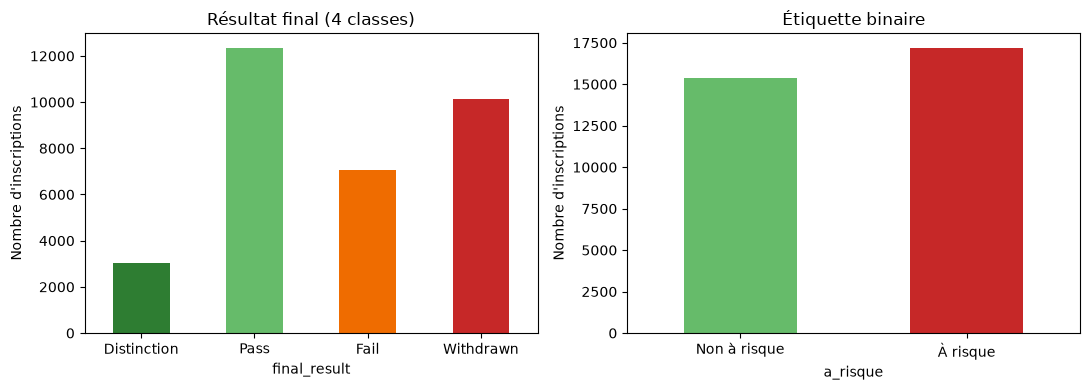

In [2]:
import matplotlib.pyplot as plt

info = tables["studentInfo"]

# Répartition des quatre résultats
repartition = info["final_result"].value_counts()
pourcentages = (repartition / len(info) * 100).round(1)
print(pd.DataFrame({"effectif": repartition, "%": pourcentages}))
print()

# Étiquette binaire « à risque » = Fail ou Withdrawn
info["a_risque"] = info["final_result"].isin(["Fail", "Withdrawn"]).astype(int)
taux_risque = info["a_risque"].mean() * 100
print(f"Apprenants à risque : {info['a_risque'].sum():,} sur {len(info):,} ({taux_risque:.1f} %)")

# Graphique
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ordre = ["Distinction", "Pass", "Fail", "Withdrawn"]
couleurs = ["#2e7d32", "#66bb6a", "#ef6c00", "#c62828"]
repartition.reindex(ordre).plot.bar(ax=axes[0], color=couleurs)
axes[0].set_title("Résultat final (4 classes)")
axes[0].set_ylabel("Nombre d'inscriptions")
axes[0].tick_params(axis="x", rotation=0)

binaire = info["a_risque"].map({0: "Non à risque", 1: "À risque"}).value_counts()
binaire.reindex(["Non à risque", "À risque"]).plot.bar(ax=axes[1], color=["#66bb6a", "#c62828"])
axes[1].set_title("Étiquette binaire")
axes[1].set_ylabel("Nombre d'inscriptions")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [3]:
# Taux d'apprenants à risque par module et par session
par_session = (info.groupby(["code_module", "code_presentation"])
                   .agg(inscriptions=("id_student", "count"),
                        taux_risque=("a_risque", "mean"))
                   .assign(taux_risque=lambda d: (d["taux_risque"] * 100).round(1))
                   .reset_index())
print(par_session.to_string(index=False))
print()
print("Sessions disponibles :", sorted(info["code_presentation"].unique()))

code_module code_presentation  inscriptions  taux_risque
        AAA             2013J           383         27.4
        AAA             2014J           365         30.7
        BBB             2013B          1767         54.6
        BBB             2013J          2237         52.1
        BBB             2014B          1613         54.9
        BBB             2014J          2292         49.7
        CCC             2014B          1936         65.8
        CCC             2014J          2498         59.4
        DDD             2013B          1303         60.9
        DDD             2013J          1938         57.2
        DDD             2014B          1228         61.0
        DDD             2014J          1803         56.1
        EEE             2013J          1052         42.1
        EEE             2014B           694         48.6
        EEE             2014J          1188         42.4
        FFF             2013B          1614         51.5
        FFF             2013J  

### Pourquoi ces métriques ? (justification de mes choix d'évaluation)

Pour illustrer, je prends un groupe de **100 apprenants dont 50 vont réellement décrocher ou échouer**.
Pour chacun, le modèle répond « à risque » (il déclenche une alerte) ou « pas à risque ».

**Les quatre cas possibles (matrice de confusion) :**

| | Le modèle dit **à risque** | Le modèle dit **pas à risque** |
|---|---|---|
| **Réellement à risque** | Vrai positif (VP) : apprenant détecté | Faux négatif (FN) : apprenant **manqué** |
| **Réellement pas à risque** | Faux positif (FP) : alerte inutile | Vrai négatif (VN) |

**Les deux erreurs n'ont pas le même coût.** Un faux positif coûte au formateur quelques minutes
(contacter un apprenant qui allait bien). Un faux négatif signifie qu'un apprenant décroche sans que
personne n'intervienne : formation abandonnée, certification perdue. Je considère donc qu'**un apprenant
manqué coûte plus cher qu'une fausse alerte**, et toutes mes métriques découlent de ce choix.

**Les métriques que je retiens :**

- **Rappel** = VP / (VP + FN) : parmi les apprenants réellement à risque, combien le modèle en détecte.
  S'il en détecte 40 sur 50, le rappel vaut 80 %. C'est **ma métrique principale**, car elle mesure
  directement le nombre d'apprenants manqués.
- **Précision** = VP / (VP + FP) : parmi les alertes déclenchées, combien sont justifiées. Si le modèle
  déclenche 60 alertes dont 40 justes, la précision vaut 67 %. Elle évite le piège d'un modèle qui
  signalerait tout le monde : son rappel serait de 100 %, mais les formateurs ignoreraient ses alertes.
- **F1** : moyenne harmonique du rappel et de la précision. Elle n'est élevée que si les deux le sont ;
  je l'utilise pour comparer rapidement les modèles.
- **ROC-AUC** : mesure la capacité du modèle à **classer** les apprenants, indépendamment du seuil.
  C'est la probabilité qu'un apprenant à risque tiré au hasard reçoive un score plus élevé qu'un
  apprenant non à risque tiré au hasard (0,5 = hasard, 1 = parfait).
- **PR-AUC** : même idée, mais calculée sur la courbe précision–rappel ; elle se concentre sur la
  classe « à risque », celle qui m'intéresse pour les alertes. C'est la plus exigeante des deux.

**Pourquoi pas l'exactitude (*accuracy*) ?** Elle compte toutes les erreurs de la même façon, ce qui
contredit mon hypothèse de coûts. Elle est aussi trompeuse quand les classes sont déséquilibrées :
avec 10 % d'apprenants à risque, un modèle qui répond toujours « pas à risque » obtiendrait 90 %
d'exactitude sans détecter personne.

**Le seuil de décision.** Le modèle ne répond pas « oui / non » mais donne une **probabilité** (par
exemple 0,37). C'est moi qui fixe le seuil au-delà duquel une alerte est déclenchée : un seuil bas
détecte plus d'apprenants (rappel élevé) mais génère plus de fausses alertes ; un seuil haut fait
l'inverse. Comme un apprenant manqué coûte plus cher, je m'attends à retenir un seuil **inférieur
à 0,5**. Je le choisirai à partir des données (étape d'évaluation), par exemple le seuil qui atteint
un rappel d'au moins 80 % tout en gardant une précision acceptable.

**Garde-fou :** quel que soit le seuil, le modèle ne décide jamais seul. Il **suggère** un niveau de
risque avec ses raisons, et c'est le formateur qui décide d'intervenir.

## 3. L'activité des apprenants sur la plateforme

La table `studentVle` contient **10,6 millions de lignes**. Chaque ligne dit : tel étudiant, tel jour,
a cliqué tant de fois sur telle ressource du cours.

Dans Cert_EET, je ne peux pas compter les clics. Je peux seulement savoir **si l'apprenant a été actif
un jour donné** (connexion). Je regarde donc surtout les **jours actifs**, pas le nombre de clics.

Ma question : **les apprenants à risque sont-ils moins actifs que les autres, et dès quand cela se
voit-il ?** Si la différence apparaît tôt, l'activité sera un bon signal pour une prédiction précoce.

Remarque : le champ `date` compte les jours depuis le début de la session. Il peut être négatif :
l'étudiant a consulté le cours avant son ouverture officielle.

In [4]:
vle = tables["studentVle"]
cle = ["code_module", "code_presentation", "id_student"]

# Un résumé par inscription : nombre de jours actifs et total des clics
activite = (vle.groupby(cle)
               .agg(jours_actifs=("date", "nunique"),
                    clics_total=("sum_click", "sum"))
               .reset_index())

# J'ajoute l'étiquette « à risque » (les inscriptions sans aucune activité ont 0 jour actif)
activite = info[cle + ["final_result", "a_risque"]].merge(activite, on=cle, how="left")
activite[["jours_actifs", "clics_total"]] = activite[["jours_actifs", "clics_total"]].fillna(0)

print("Inscriptions sans aucune activité :", (activite["jours_actifs"] == 0).sum())
print()
print(activite.groupby("final_result")[["jours_actifs", "clics_total"]].median()
              .reindex(["Distinction", "Pass", "Fail", "Withdrawn"]))

Inscriptions sans aucune activité : 3365

              jours_actifs  clics_total
final_result                           
Distinction          103.0       1896.0
Pass                  78.0       1343.0
Fail                  22.0        317.0
Withdrawn              7.0         89.0


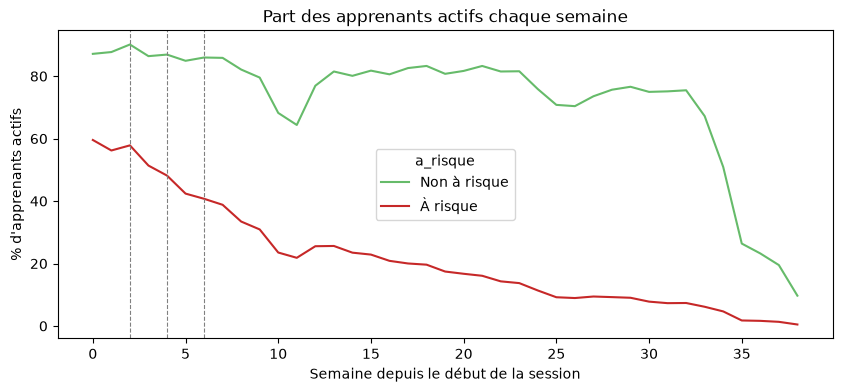

In [5]:
# Pour chaque semaine : part des apprenants qui ont été actifs au moins une fois
vle_sem = vle.assign(semaine=vle["date"] // 7)
actifs = (vle_sem[vle_sem["semaine"].between(0, 38)]
            .drop_duplicates(cle + ["semaine"])
            .merge(info[cle + ["a_risque"]], on=cle))

effectifs = info.groupby("a_risque").size()
courbe = actifs.groupby(["semaine", "a_risque"]).size().unstack() / effectifs * 100

ax = courbe.rename(columns={0: "Non à risque", 1: "À risque"}).plot(
        figsize=(10, 4), color=["#66bb6a", "#c62828"])
ax.set_title("Part des apprenants actifs chaque semaine")
ax.set_xlabel("Semaine depuis le début de la session")
ax.set_ylabel("% d'apprenants actifs")
for s in [2, 4, 6]:   # mes futures dates de prédiction : J+14, J+28, J+42
    ax.axvline(s, color="grey", linestyle="--", linewidth=0.8)
plt.show()

### Mes constats sur l'activité

**1. Les apprenants à risque sont beaucoup moins actifs.** En médiane, un étudiant qui réussit avec
mention a été actif **103 jours**, un étudiant qui réussit **78 jours**, un étudiant qui échoue
**22 jours** et un étudiant qui abandonne seulement **7 jours**. L'écart est très net.

**2. La différence se voit dès le début.** Dès la semaine 0, environ 87 % des apprenants « non à
risque » sont actifs, contre environ 60 % des apprenants « à risque ». À mes dates de prédiction
(lignes grises : semaines 2, 4 et 6), l'écart grandit : il passe d'environ 30 à 45 points.
Une **prédiction précoce est donc possible** : pas besoin d'attendre la fin de la session.

**3. Une baisse commune vers la semaine 10–11.** Les deux groupes baissent en même temps. Pour les
sessions qui commencent en octobre, cela correspond aux vacances de fin d'année. Ce n'est pas un
signe de décrochage : je devrai comparer l'activité d'un apprenant à celle de son groupe, pas à
une valeur fixe.

**4. La chute finale (après la semaine 33) est normale** : c'est la fin de la session pour tout le monde.

**5. 3 365 inscriptions n'ont aucune activité.** Une partie de ces étudiants s'est désinscrite
avant même le début du cours. Pour eux, une prédiction n'a pas de sens : ils sont déjà partis.
**Ma décision :** à chaque date de prédiction, je garde seulement les apprenants **encore inscrits
à cette date**. Sinon, le modèle paraîtrait meilleur qu'il ne l'est, en « prédisant » des abandons
déjà connus.

**Lien avec Cert_EET :** mes variables d'activité seront des **jours actifs** (actif ou non chaque
jour), car c'est ce que Cert_EET enregistre aujourd'hui. Le volume de clics n'est pas transposable.

## 4. Les évaluations : remises, notes et retards

Deux tables décrivent les évaluations :
- `assessments` : la liste des évaluations de chaque cours, avec leur **type** et leur **date limite** ;
- `studentAssessment` : ce que chaque étudiant a rendu, **quand**, et avec quelle **note** (sur 100).

Il existe trois types d'évaluations :
- **TMA** : devoir corrigé par un tuteur. C'est l'équivalent des **ateliers** de Cert_EET (livrable + date limite + note) ;
- **CMA** : quiz corrigé automatiquement. C'est l'équivalent des **QCM** de Cert_EET ;
- **Exam** : examen final. Il arrive en fin de session, donc **après** mes dates de prédiction : je ne l'utilise pas.

Comme décidé plus haut, je remplace la date manquante des examens par la durée de la session.

Mes questions : les apprenants à risque rendent-ils moins de travaux, plus en retard, avec de moins
bonnes notes ? Et surtout : **la toute première évaluation suffit-elle déjà à les repérer ?**

In [6]:
ass = tables["assessments"].merge(tables["courses"], on=["code_module", "code_presentation"])
# Date manquante des examens = fin de la session
ass["date"] = ass["date"].fillna(ass["module_presentation_length"])

print("Évaluations par type :")
print(ass["assessment_type"].value_counts())
print()

# Remises des étudiants + infos de l'évaluation + étiquette
remises = (tables["studentAssessment"]
             .merge(ass[["id_assessment", "code_module", "code_presentation", "assessment_type", "date"]],
                    on="id_assessment")
             .merge(info[cle + ["a_risque"]], on=cle))
remises["retard_jours"] = remises["date_submitted"] - remises["date"]
remises["en_retard"] = remises["retard_jours"] > 0
remises["echec"] = remises["score"] < 40   # seuil de réussite utilisé par l'Open University

resume = (remises[remises["assessment_type"] != "Exam"]
            .groupby("a_risque")
            .agg(note_moyenne=("score", "mean"),
                 part_en_retard=("en_retard", "mean"),
                 part_echecs=("echec", "mean"))
            .rename(index={0: "Non à risque", 1: "À risque"}))
resume["part_en_retard"] = (resume["part_en_retard"] * 100).round(1)
resume["part_echecs"] = (resume["part_echecs"] * 100).round(1)
print(resume.round(1))    

Évaluations par type :
assessment_type
TMA     106
CMA      76
Exam     24
Name: count, dtype: int64

              note_moyenne  part_en_retard  part_echecs
a_risque                                               
Non à risque          79.4            26.0          1.9
À risque              65.6            39.0         11.3


#### La première évaluation : un signal précoce ?

In [7]:
# Première évaluation (hors examen) de chaque cours
premiere = (ass[ass["assessment_type"] != "Exam"]
              .sort_values("date")
              .groupby(["code_module", "code_presentation"])
              .head(1)[["id_assessment", "code_module", "code_presentation", "date"]])
print("Date limite de la première évaluation (jours) :", sorted(premiere["date"].astype(int).unique().tolist()))
print()

# Pour chaque inscription : a-t-il rendu la première évaluation ? quelle note ?
p = info[cle + ["a_risque"]].merge(premiere, on=["code_module", "code_presentation"])
p = p.merge(tables["studentAssessment"][["id_assessment", "id_student", "score"]],
            on=["id_assessment", "id_student"], how="left")
p["rendue"] = p["score"].notna()

print(p.groupby("a_risque")
       .agg(part_rendue=("rendue", "mean"), note_moyenne=("score", "mean"))
       .rename(index={0: "Non à risque", 1: "À risque"})
       .assign(part_rendue=lambda d: (d["part_rendue"] * 100).round(1))
       .round(1))

Date limite de la première évaluation (jours) : [12, 18, 19, 20, 23, 24, 25, 33, 61]

              part_rendue  note_moyenne
a_risque                               
Non à risque         99.1          77.4
À risque             58.7          66.2


### Mes constats sur les évaluations

**1. Les apprenants à risque ont de moins bonnes notes, rendent plus en retard et échouent plus.**

| | Non à risque | À risque |
|---|---|---|
| Note moyenne (sur 100) | 79,4 | 65,6 |
| Remises en retard | 26,0 % | 39,0 % |
| Notes en échec (< 40) | 1,9 % | 11,3 % |

Ces trois signaux existent aussi dans Cert_EET (notes des QCM et des ateliers, livrables en retard).
Ils correspondent d'ailleurs à trois règles actuelles de l'application : `ECHECS_QCM`,
`LIVRABLE_EN_RETARD` et `SCORE_EN_CHUTE`.

**2. La première évaluation est un signal précoce très fort.** Sa date limite tombe entre le 12e et
le 20e jour environ, donc avant ou autour de mes premières dates de prédiction. Or :
- **99,1 %** des apprenants non à risque la rendent ;
- seulement **58,7 %** des apprenants à risque la rendent.

Ne pas rendre la première évaluation est donc presque toujours un mauvais signe. La note compte
aussi (77,4 contre 66,2), mais beaucoup moins que le simple fait de rendre ou non.

**3. Une précaution importante.** Ces chiffres utilisent **toute** la session. Ils servent seulement
à comprendre les données. Pour le modèle, je calculerai chaque variable **uniquement avec les
évaluations dont la date limite est passée à la date de prédiction**. Exemple : à J+14, une
évaluation dont la date limite est J+19 ne compte pas encore, ni comme « rendue » ni comme
« non rendue ». Sinon, le modèle utiliserait des informations du futur (fuite de données).

## 5. Les variables personnelles (pour l'audit d'équité uniquement)

La table `studentInfo` contient aussi des informations personnelles : **genre**, **tranche d'âge**,
**handicap**, région, niveau d'études et indice de défavorisation (IMD).

**Ma décision : je n'utilise aucune de ces variables comme entrée du modèle.** Deux raisons :
- **Équité** : le niveau de risque d'un apprenant ne doit pas dépendre de qui il est, mais de ce qu'il fait
  (activité, remises, notes) ;
- **Transposition** : Cert_EET ne connaît ni le genre, ni le handicap, ni l'IMD de ses apprenants.

Je garde quand même le genre, l'âge et le handicap **à part**, pour une seule chose : vérifier plus tard
que le modèle fonctionne **aussi bien pour tous les groupes** (audit d'équité). Ici, je regarde
simplement la taille de chaque groupe et son taux de risque.

In [8]:
for col in ["gender", "age_band", "disability"]:
    t = (info.groupby(col)
             .agg(effectif=("id_student", "count"), taux_risque=("a_risque", "mean"))
             .assign(part=lambda d: (d["effectif"] / len(info) * 100).round(1),
                     taux_risque=lambda d: (d["taux_risque"] * 100).round(1)))
    print(f"--- {col} ---")
    print(t[["effectif", "part", "taux_risque"]])
    print()

--- gender ---
        effectif  part  taux_risque
gender                             
F          14718  45.2         51.6
M          17875  54.8         53.8

--- age_band ---
          effectif  part  taux_risque
age_band                             
0-35         22944  70.4         55.0
35-55         9433  28.9         47.8
55<=           216   0.7         38.4

--- disability ---
            effectif  part  taux_risque
disability                             
N              29429  90.3         51.8
Y               3164   9.7         61.9



### Mes constats sur les variables personnelles

**1. Genre : peu de différence.** Les femmes (45,2 %) ont un taux de risque de 51,6 %, les hommes
(54,8 %) de 53,8 %. L'écart est faible (2 points).

**2. Âge : les plus jeunes sont plus à risque.** 55,0 % pour les 0–35 ans, 47,8 % pour les 35–55 ans,
38,4 % pour les plus de 55 ans. Mais le groupe des plus de 55 ans ne compte que **216 inscriptions
(0,7 %)** : c'est trop peu pour tirer des conclusions fiables. **Pour l'audit d'équité, je regrouperai
donc les 35–55 et les plus de 55 ans en un seul groupe « 35 ans et plus ».**

**3. Handicap : un écart net.** Les apprenants déclarant un handicap (9,7 %) ont un taux de risque de
**61,9 %**, contre 51,8 % pour les autres, soit 10 points de plus.

**Ce que cela implique pour mon modèle.** Même si ces variables ne sont pas des entrées, le modèle
peut traiter les groupes différemment. Par exemple, si un handicap réduit l'activité en ligne pour
d'autres raisons que le décrochage, le modèle pourrait générer plus d'alertes pour ce groupe, ou au
contraire en manquer certains.

Comme les taux de risque réels ne sont pas les mêmes d'un groupe à l'autre, je ne comparerai pas
simplement le nombre d'alertes. Je vérifierai surtout que le **rappel** (part des apprenants à risque
détectés) et la **précision** restent proches dans chaque groupe : un apprenant à risque doit avoir
la même chance d'être repéré, quel que soit son genre, son âge ou son handicap.

## 6. Synthèse de l'exploration

**Ce que j'ai appris sur les données :**
1. Les 7 tables sont complètes (tailles conformes à la publication). Les valeurs manquantes ont
   chacune une explication, et je les traite au cas par cas.
2. 52,8 % des inscriptions sont « à risque » (Fail ou Withdrawn) : les classes sont presque équilibrées.
   L'abandon (31,2 %) pèse plus que l'échec (21,6 %).
3. **L'activité est le signal le plus fort**, et elle se voit dès la première semaine.
4. **La première évaluation est un signal précoce très fort** : 99 % des apprenants non à risque la
   rendent, contre 59 % des apprenants à risque.
5. Les notes, les retards et les échecs confirment ces tendances. Ils correspondent aux règles
   actuelles de Cert_EET.

**Mes décisions pour la suite :**
- **Cible :** à risque = Fail ou Withdrawn.
- **Dates de prédiction :** J+14, J+28, J+42… Je garde seulement les apprenants encore inscrits à
  chaque date, et je n'utilise **aucune information postérieure** à cette date.
- **Variables :** uniquement des signaux disponibles aussi dans Cert_EET (jours actifs, remises,
  retards, notes). Pas de clics, pas de module, pas de variables personnelles.
- **Découpage :** entraînement sur 2013B, 2013J et 2014B ; test sur 2014J (toujours tester sur
  une session plus récente).
- **Métriques :** rappel en priorité, avec précision, F1, ROC-AUC et PR-AUC. Le seuil sera choisi
  en fonction du coût d'un apprenant manqué.
- **Équité :** genre, âge et handicap servent seulement à vérifier que le modèle est aussi bon
  pour tous les groupes.

**Prochaine étape :** construire les variables à chaque date de prédiction (notebook `02_variables`).